### Ant Colony Optimization (ACO) for Protein Structure Prediction (2D HP Model)

In the HP model:
- **H (Hydrophobic)** monomers prefer to be close to each other, avoiding water.
- **P (Polar)** monomers prefer to be on the outside.
- We seek a conformation on a 2D grid (steps: Left, Right, Up, Down) that is **self-avoiding** (no two monomers occupy the same grid coordinate) and maximizes the number of topological H-H contacts (adjacent on the grid but not in the sequence).

In [1]:
import numpy as np
import random
import matplotlib.pyplot as plt

# Define the protein sequence (H = Hydrophobic, P = Polar)
# Example sequence: HPHPPHHPHPPHPHHP
PROTEIN_SEQ = "HPHPPHHPHPPHPHHP"

# Directions: Right, Up, Left, Down
DIRECTIONS = [(1, 0), (0, 1), (-1, 0), (0, -1)]

class AntColonyProteinFolding:
    def __init__(self, sequence, num_ants=10, generations=50, alpha=1.0, beta=2.0, decay=0.2, q=1.0):
        self.sequence = sequence
        self.N = len(sequence)
        self.num_ants = num_ants
        self.generations = generations
        self.alpha = alpha      # Pheromone importance
        self.beta = beta        # Heuristic importance
        self.decay = decay      # Pheromone evaporation rate
        self.q = q              # Pheromone deposit factor

        # Initialize pheromone matrix: pheromone[step_index][direction_index]
        self.pheromone = np.ones((self.N - 1, 4)) * 0.1

    def calculate_contacts(self, path):
        """Calculate hydrophobic (H-H) contacts that are adjacent on grid but not in sequence."""
        coords = {}
        for i, coord in enumerate(path):
            coords[coord] = self.sequence[i]

        h_contacts = 0
        # Check each pair of H monomers
        h_positions = [path[i] for i in range(self.N) if self.sequence[i] == 'H']

        for i in range(len(h_positions)):
            for j in range(i + 1, len(h_positions)):
                # Check if they are sequential in sequence
                idx_i = path.index(h_positions[i])
                idx_j = path.index(h_positions[j])
                if abs(idx_i - idx_j) == 1:
                    continue

                # Check Manhattan distance on the grid
                dist = abs(h_positions[i][0] - h_positions[j][0]) + abs(h_positions[i][1] - h_positions[j][1])
                if dist == 1:
                    h_contacts += 1
        return h_contacts

    def get_valid_moves(self, current_pos, visited):
        valid = []
        for i, d in enumerate(DIRECTIONS):
            next_pos = (current_pos[0] + d[0], current_pos[1] + d[1])
            if next_pos not in visited:
                valid.append((i, next_pos))
        return valid

    def run(self):
        best_path = None
        best_score = -1
        history = []

        for gen in range(self.generations):
            all_paths = []
            scores = []

            for ant in range(self.num_ants):
                # Start at origin (0,0)
                path = [(0, 0)]
                visited = {(0, 0)}
                dead_end = False

                for step in range(self.N - 1):
                    current_pos = path[-1]
                    valid_moves = self.get_valid_moves(current_pos, visited)

                    if not valid_moves:
                        dead_end = True
                        break

                    # Calculate probabilities for valid moves
                    probabilities = []
                    for dir_idx, next_pos in valid_moves:
                        # Pheromone level for this step and direction
                        tau = self.pheromone[step][dir_idx]

                        # Heuristic: Prefer moves that place 'H' adjacent to existing 'H's
                        eta = 1.0
                        if self.sequence[step + 1] == 'H':
                            # Count surrounding H's already placed
                            h_count = 0
                            for d in DIRECTIONS:
                                neighbor = (next_pos[0] + d[0], next_pos[1] + d[1])
                                if neighbor in visited and self.sequence[path.index(neighbor)] == 'H':
                                    h_count += 1
                            eta += h_count

                        probabilities.append((tau ** self.alpha) * (eta ** self.beta))

                    prob_sum = sum(probabilities)
                    if prob_sum == 0:
                        probabilities = [1.0 / len(valid_moves)] * len(valid_moves)
                    else:
                        probabilities = [p / prob_sum for p in probabilities]

                    # Choose next direction
                    chosen_idx = np.random.choice(len(valid_moves), p=probabilities)
                    dir_idx, next_pos = valid_moves[chosen_idx]

                    path.append(next_pos)
                    visited.add(next_pos)

                if not dead_end:
                    score = self.calculate_contacts(path)
                    all_paths.append((path, score))
                    scores.append(score)

                    if score > best_score:
                        best_score = score
                        best_path = path

            # Evaporate pheromones
            self.pheromone *= (1 - self.decay)

            # Update pheromones based on successful completed paths
            for path, score in all_paths:
                for step in range(self.N - 1):
                    # Reconstruct direction taken
                    dx = path[step+1][0] - path[step][0]
                    dy = path[step+1][1] - path[step][1]
                    dir_idx = DIRECTIONS.index((dx, dy))
                    # Deposit pheromone proportionally to conformation score
                    self.pheromone[step][dir_idx] += self.q * (score + 1)

            avg_score = np.mean(scores) if scores else 0
            history.append(best_score)
            if (gen + 1) % 10 == 0 or gen == 0:
                print(f"Generation {gen+1:02d} | Best H-H Contacts: {best_score} | Average: {avg_score:.2f}")

        return best_path, best_score, history

# Run the ACO algorithm
aco = AntColonyProteinFolding(sequence=PROTEIN_SEQ, num_ants=25, generations=60, alpha=1.0, beta=1.5, decay=0.1)
best_path, best_score, history = aco.run()


Generation 01 | Best H-H Contacts: 3 | Average: 1.12
Generation 10 | Best H-H Contacts: 5 | Average: 1.40
Generation 20 | Best H-H Contacts: 5 | Average: 1.79
Generation 30 | Best H-H Contacts: 5 | Average: 1.68
Generation 40 | Best H-H Contacts: 6 | Average: 2.08
Generation 50 | Best H-H Contacts: 6 | Average: 1.60
Generation 60 | Best H-H Contacts: 6 | Average: 1.74


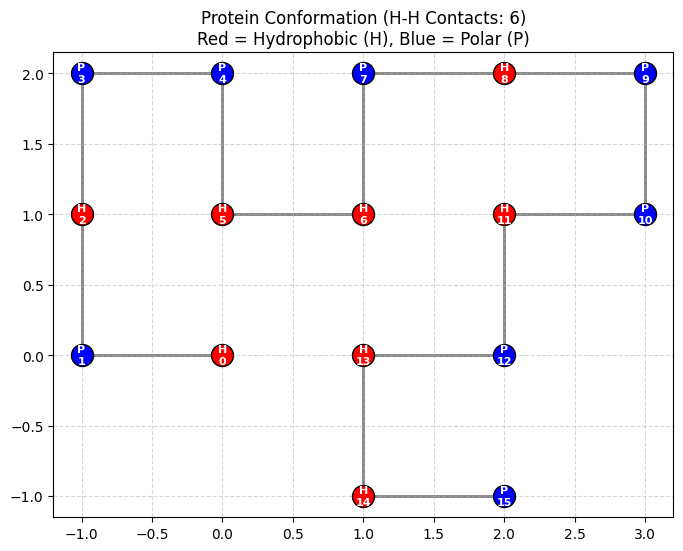

In [2]:
def plot_protein(path, sequence, score):
    x = [p[0] for p in path]
    y = [p[1] for p in path]

    plt.figure(figsize=(8, 8))
    # Plot backbone
    plt.plot(x, y, '-', color='gray', zorder=1, lw=2)

    # Plot monomers
    for i, (px, py) in enumerate(path):
        color = 'red' if sequence[i] == 'H' else 'blue'
        plt.scatter(px, py, color=color, s=250, zorder=2, edgecolors='black')
        plt.text(px, py, f"{sequence[i]}\n{i}", ha='center', va='center', color='white', fontweight='bold', fontsize=8)

    plt.title(f"Protein Conformation (H-H Contacts: {score})\nRed = Hydrophobic (H), Blue = Polar (P)")
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.gca().set_aspect('equal', adjustable='box')
    plt.show()

if best_path:
    plot_protein(best_path, PROTEIN_SEQ, best_score)
else:
    print("No valid path found.")
